In [89]:
import numpy as np
import matplotlib.pyplot as plt

In [90]:
def rk4(f, t0, y0, h, n):
  """
  Solves an ODE using the 4th-order Runge-Kutta method.

  Parameters:
    f: function - The derivative function dy/dt = f(t, y)
    t0: float   - Initial time
    y0: ndarray - Initial value of y
    h: float    - Step size
    n: int      - Number of steps

  Returns:
    t_vals: array - Time values
    y_vals: array - Approximated solution at each time step
  """
  t_vals = np.zeros(n+1)
  y_vals = np.zeros(n+1)
  t_vals[0], y_vals[0] = t0, y0
  for i in range(n):
    t, y = t_vals[i], y_vals[i]
    k1 = h * f(t, y)
    k2 = h * f(t+h/2, y+k1/2)
    k3 = h * f(t+h/2, y+k2/2)
    k4 = h * f(t+h, y+k3)
    y_vals[i+1] = y + (k1 + 2*k2 + 2*k3 + k4) / 6
    t_vals[i+1] = t + h
  return t_vals, y_vals

In [91]:
# Example ODE: dy/dt = -2y, y(0) = 1
def example_ode(t, y):
  return -2 * y

In [92]:
# Example ODE without exact solution: dy/dt = y^2 - t
def complex_ode(t, y):
  return y**2 - t

In [93]:
def solve_and_plot(f, t0, y0, h, n, exact_sol=None, title='Runge-Kutta 4th Order Method'):
  t_vals, y_vals = rk4(f, t0, y0, h, n)
  plt.figure(figsize=(10, 5))
  plt.subplot(1, 2, 1)
  plt.plot(t_vals, y_vals, 'bo-', label='RK4 Approximation')
  if exact_sol is not None:
    y_exact = exact_sol(t_vals)
    plt.plot(t_vals, y_exact, 'r-', label='Exact Solution')
    # Compute and plot the error
    error = np.abs(y_vals - y_exact)
    plt.subplot(1, 2, 2)
    plt.plot(t_vals, error, 'k-', label='Error')
    plt.xlabel('t')
    plt.ylabel('Error')
    plt.title('RK4 Error Plot')
    plt.legend()
    plt.grid()
  plt.subplot(1, 2, 1)
  plt.xlabel('t')
  plt.ylabel('y')
  plt.legend()
  plt.title(title)
  plt.grid()
  plt.tight_layout()
  plt.show()

In [94]:
# Parameters
t0, y0 = 0, 1    # Initial conditions
h = 0.01         # Step Size
n = 50           # Number of steps

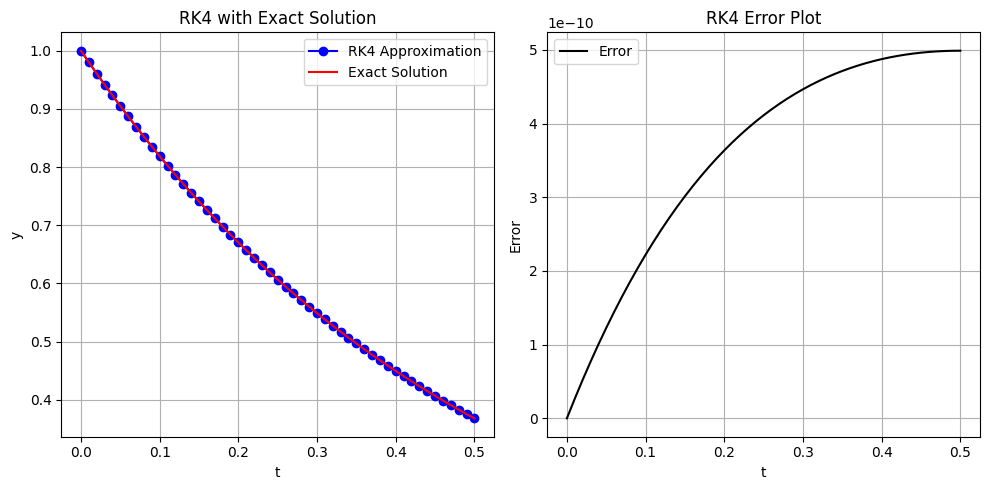

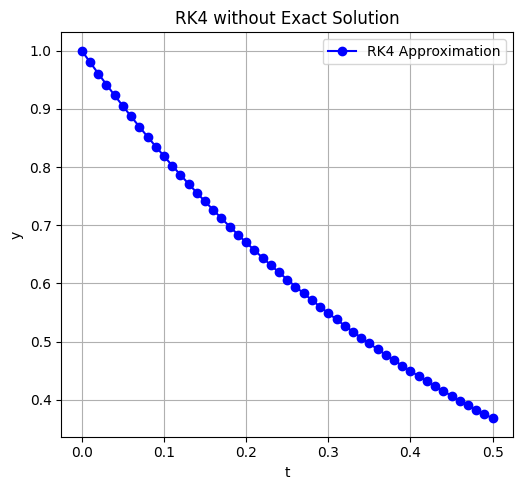

In [95]:
# Solve and plot for both cases
solve_and_plot(example_ode, t0, y0, h, n, exact_sol=lambda t: y0 * np.exp(-2*t), title="RK4 with Exact Solution")
solve_and_plot(example_ode, t0, y0, h, n, title="RK4 without Exact Solution")